In [12]:
from typing import Annotated, Literal
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages
from pydantic import BaseModel, Field
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

load_dotenv()

True

## Agent State

In [13]:
class AgentState(TypedDict):
    messages: Annotated[list, add_messages]
    intent: str

## Intent State

In [14]:
class Intent(BaseModel):
    intent: Literal["qa","summarization"] = Field(
        description="Determine the user's intent."
    )

In [15]:
router_llm = ChatGroq(model="llama-3.3-70b-versatile",temperature=0)
router_llm = router_llm.with_structured_output(Intent)

## Node for Determining Intent

In [16]:
def intent_router(state: AgentState):

    last_message = state["messages"][-1].content

    result = router_llm.invoke(
        [
            HumanMessage(
                content=last_message
            )
        ]
    )

    return {
        "intent": result.intent
    }

## Node for qa

In [17]:
qa_llm = ChatGroq(model="openai/gpt-oss-safeguard-20b")

def qa_agent(state):

    response = qa_llm.invoke(state["messages"])

    return {
        "messages": [response]
    }

## Node for summarizer

In [18]:
summary_llm = ChatGroq(model="openai/gpt-oss-safeguard-20b")

def summarizer_agent(state):

    response = summary_llm.invoke(
        [
            (
                "system",
                "You are an expert summarizer."
            ),
            *state["messages"]
        ]
    )

    return {
        "messages": [response]
    }

## Routing Function

In [19]:
def route(state: AgentState):

    return state["intent"]

## Graph Definition

In [20]:

builder = StateGraph(AgentState)

builder.add_node("router", intent_router)
builder.add_node("qa", qa_agent)
builder.add_node("summarization", summarizer_agent)

builder.add_edge(START, "router")

builder.add_conditional_edges(
    "router",
    route,
    {
        "qa": "qa",
        "summarization": "summarization"
    }
)

builder.add_edge("qa", END)
builder.add_edge("summarization", END)

graph = builder.compile()

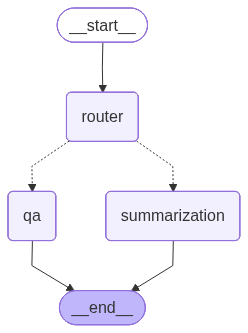

In [21]:
graph

In [23]:
graph.invoke(
    {
        "messages": [
            HumanMessage(
                content="Summarize universe"
            )
        ]
    }
)

{'messages': [HumanMessage(content='Summarize universe', additional_kwargs={}, response_metadata={}, id='9c7564b9-21e2-45f3-82dc-e054b2a6834a'),
  AIMessage(content='**A One‑Page Overview of the Universe**\n\n| Theme | Key Points |\n|-------|------------|\n| **Origin & Big Bang** | • ~13.8\u202fbillion years ago: all matter, energy, space, and time were concentrated in a hot, dense state. <br>• Rapid inflation stretched the universe, smoothing out irregularities. <br>• Expansion continues today, driven by a mysterious dark‑energy component (~70\u202f% of the total energy density). |\n| **Cosmic Composition** | • Ordinary (baryonic) matter: ~5\u202f% (stars, gas, planets, life). <br>• Dark matter: ~27\u202f% (exerts gravity, forms galactic halos; particle nature still unknown). <br>• Dark energy: ~68\u202f% (accelerating expansion). |\n| **Structure Formation** | • Quantum fluctuations in the early universe seeded density variations. <br>• Gravity amplified these into the first stars an